# PLEIAData – Data Description, Cleaning, Preparation and EDA

**Digital Twins (530.091) · Submission 2 · Pleiades building, University of Murcia**

**Objective:** forecast the hourly electricity use of each building block (A, B, C) from weather and HVAC operation, as the basis of a digital model of the building.

**Structure:** 1 Description · 2 Cleaning · 3 Preparation · 4 EDA · 5 Gaps and limitations

We work with the **raw data**, so that every cleaning decision is our own and can be justified.

In [1]:
# ! pip install numpy pandas matplotlib seaborn scikit-learn

In [2]:
import os, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import FancyBboxPatch, Patch
import seaborn as sns

RAW = "../Data/raw_data/"
OUT = "../Data/prepared/"
TZ = "Europe/Madrid"
BLOCKS = ["A", "B", "C"]
MONTHS = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", red="#e34948", ink="#0b0b0b",
         ink2="#52514e", muted="#898781", grid="#e1e0d9", surf="#fcfcfb")
BCOL = {"A": C["blue"], "B": C["orange"], "C": C["aqua"]}
plt.rcParams.update({
    "figure.facecolor": C["surf"], "axes.facecolor": C["surf"], "savefig.facecolor": C["surf"],
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": C["ink2"], "axes.titlecolor": C["ink"],
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": C["grid"], "grid.linewidth": 0.6, "xtick.color": C["muted"], "ytick.color": C["muted"],
    "lines.linewidth": 1.8, "legend.frameon": False, "figure.dpi": 110, "font.size": 10})
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 80)

def to_utc(s):
    return pd.to_datetime(s, utc=True, format="ISO8601")

## 1. Description

### 1.1 Source and files

* **Dataset:** PLEIAData – Martínez Ibarra, González-Vidal & Skarmeta, *Scientific Data* 10, 118 (2023). DOI 10.1038/s41597-023-02023-3
* **Download:** Zenodo, https://zenodo.org/records/7620136 (folder `raw_data`)
* **System:** Pleiades building, University of Murcia (Spain), three blocks A, B, C
* **Period:** 1 Jan – 31 Dec 2021

In [3]:
files = pd.DataFrame([
    ("data-cons.csv",           "electricity meters, one per block (cumulative kWh)"),
    ("data-hvac.csv",           "HVAC units: on/off, mode, setpoint, unit type"),
    ("data-sensor.csv",         "room temperature sensors (and other devices)"),
    ("MU62_dm.txt",             "weather station MU62 (IMIDA), Murcia"),
    ("relations-hvac.csv",      "HVAC unit ID -> block, room"),
    ("relations-sensor.csv",    "temperature sensor ID -> block, room"),
    ("data-CO2.csv",            "CO2 in 12 rooms (blocks A, B) - not used in this stage"),
    ("data-presence.csv",       "motion sensors in 12 rooms (blocks A, B) - not used in this stage"),
], columns=["file", "content"])
files["size (MB)"] = [round(os.path.getsize(RAW + f) / 1e6, 1) for f in files.file]
files

,file,content,size (MB)
0,data-cons.csv,"electricity meters, one per block (cumulative kWh)",9.2
1,data-hvac.csv,"HVAC units: on/off, mode, setpoint, unit type",220.6
2,data-sensor.csv,room temperature sensors (and other devices),504.7
3,MU62_dm.txt,"weather station MU62 (IMIDA), Murcia",6.6
4,relations-hvac.csv,"HVAC unit ID -> block, room",0.0
5,relations-sensor.csv,"temperature sensor ID -> block, room",0.0
6,data-CO2.csv,"CO2 in 12 rooms (blocks A, B) - not used in this stage",561.9
7,data-presence.csv,"motion sensors in 12 rooms (blocks A, B) - not used in this stage",12.5


### 1.2 Loading

All raw files store one row per device reading: `IDdevice`, `Date` (ISO time with UTC offset) and generic value columns. We convert every timestamp to **UTC**. The weather file has no offset; its solar radiation peaks at about 12:00 in both January and July, so it is already in UTC.

In [4]:
# Electricity: the meter IDs are documented in the authors' notebook
METER = {335546928: "A", 335546926: "B", 335546927: "C"}
cons_raw = pd.read_csv(RAW + "data-cons.csv", sep=";")
cons_raw["Date"] = to_utc(cons_raw["Date"])
cons_raw["block"] = cons_raw["IDdevice"].map(METER)

# HVAC log
hvac_raw = pd.read_csv(RAW + "data-hvac.csv", sep=";", usecols=["IDdevice", "Date", "V4", "V5", "V12", "V26"])
hvac_raw["Date"] = to_utc(hvac_raw["Date"])
rel_h = pd.read_csv(RAW + "relations-hvac.csv", sep=";")

# Temperature: the file also holds other device types; we keep the IDs listed in relations-sensor.csv
rel_s = pd.read_csv(RAW + "relations-sensor.csv", sep=";")
ids_in_file, parts = set(), []
for ch in pd.read_csv(RAW + "data-sensor.csv", sep=";", usecols=["IDdevice", "Date", "V2"], chunksize=2_000_000):
    ids_in_file |= set(ch["IDdevice"].unique())
    parts.append(ch[ch["IDdevice"].isin(rel_s["ID"])])
temp_raw = pd.concat(parts, ignore_index=True)
temp_raw["Date"] = to_utc(temp_raw["Date"])
temp_raw = temp_raw.merge(rel_s.rename(columns={"ID": "IDdevice"}), on="IDdevice", how="left")

# Weather
w = pd.read_csv(RAW + "MU62_dm.txt", sep=";", skipinitialspace=True)
w.columns = [c.strip() for c in w.columns]
w["Date"] = pd.to_datetime(w["fecha"] + " " + w["hora"], format="%d/%m/%y %H:%M:%S").dt.tz_localize("UTC")
weather_raw = w.set_index("Date")[["tmed", "hrmed", "radmed", "vvmed", "dvmed", "prec", "dewpt"]].sort_index()

for name, d in [("electricity", cons_raw), ("HVAC", hvac_raw), ("temperature", temp_raw)]:
    print(f"{name:12s}: {len(d):>10,} rows | {d['IDdevice'].nunique():>3} devices | {d['Date'].min():%d %b %Y} -> {d['Date'].max():%d %b %Y}")
print(f"{'weather':12s}: {len(weather_raw):>10,} rows |   1 station | {weather_raw.index.min():%d %b %Y} -> {weather_raw.index.max():%d %b %Y}")

electricity :    154,833 rows |   3 devices | 31 Dec 2020 -> 31 Dec 2021
HVAC        :  4,339,076 rows |  88 devices | 31 Dec 2020 -> 31 Dec 2021
temperature :  3,303,131 rows |  64 devices | 31 Dec 2020 -> 31 Dec 2021
weather     :     55,713 rows |   1 station | 01 Jan 2021 -> 20 Feb 2022


### 1.3 Signals

In [5]:
def median_interval(d):
    return d.sort_values(["IDdevice", "Date"]).groupby("IDdevice")["Date"].diff().median().total_seconds() / 60

iv_cons, iv_hvac, iv_temp = median_interval(cons_raw), median_interval(hvac_raw), median_interval(temp_raw)
iv_w = weather_raw.index.to_series().diff().median().total_seconds() / 60
signals = pd.DataFrame([
    ("V22",    "data-cons",  "electricity meter reading, cumulative",            "kWh",   iv_cons, "3 meters (one per block)",         "output y"),
    ("V4",     "data-hvac",  "HVAC unit state: 0 = off, 1 = on",                  "-",     iv_hvac, f"{hvac_raw.IDdevice.nunique()} units, reported by the unit", "input u"),
    ("V5",     "data-hvac",  "mode: 0 none, 1 heating, 2 cooling, 3 dry, 4 fan",  "-",     iv_hvac, "reported by the unit",             "input u"),
    ("V12",    "data-hvac",  "setpoint chosen by the user",                       "°C",    iv_hvac, "reported by the unit",             "input u"),
    ("V26",    "data-hvac",  "unit type: 1 wall, 2 ceiling",                      "-",     iv_hvac, "fixed per unit",                   "metadata"),
    ("V2",     "data-sensor","room air temperature",                              "°C",    iv_temp, f"{temp_raw.IDdevice.nunique()} sensors with data", "state x"),
    ("tmed",   "MU62",       "outdoor air temperature (10-min mean)",             "°C",    iv_w,    "weather station MU62",             "disturbance d"),
    ("hrmed",  "MU62",       "outdoor relative humidity",                         "%",     iv_w,    "weather station MU62",             "disturbance d"),
    ("radmed", "MU62",       "global solar radiation",                            "W/m²",  iv_w,    "weather station MU62",             "disturbance d"),
    ("vvmed",  "MU62",       "wind speed",                                        "m/s",   iv_w,    "weather station MU62",             "disturbance d"),
    ("dvmed",  "MU62",       "wind direction",                                    "°",     iv_w,    "weather station MU62",             "disturbance d"),
    ("prec",   "MU62",       "precipitation",                                     "mm",    iv_w,    "weather station MU62",             "disturbance d"),
    ("dewpt",  "MU62",       "dew point",                                         "°C",    iv_w,    "weather station MU62",             "disturbance d"),
], columns=["signal", "file", "meaning", "unit", "interval (min)", "measurement", "canvas role"])
signals["interval (min)"] = signals["interval (min)"].round(0).astype(int)
signals

,signal,file,meaning,unit,interval (min),measurement,canvas role
0,V22,data-cons,"electricity meter reading, cumulative",kWh,10,3 meters (one per block),output y
1,V4,data-hvac,"HVAC unit state: 0 = off, 1 = on",-,10,"88 units, reported by the unit",input u
2,V5,data-hvac,"mode: 0 none, 1 heating, 2 cooling, 3 dry, 4 fan",-,10,reported by the unit,input u
3,V12,data-hvac,setpoint chosen by the user,°C,10,reported by the unit,input u
4,V26,data-hvac,"unit type: 1 wall, 2 ceiling",-,10,fixed per unit,metadata
5,V2,data-sensor,room air temperature,°C,10,64 sensors with data,state x
6,tmed,MU62,outdoor air temperature (10-min mean),°C,10,weather station MU62,disturbance d
7,hrmed,MU62,outdoor relative humidity,%,10,weather station MU62,disturbance d
8,radmed,MU62,global solar radiation,W/m²,10,weather station MU62,disturbance d
9,vvmed,MU62,wind speed,m/s,10,weather station MU62,disturbance d


**Notes**
* All signals are logged about every **10 minutes**; the HVAC and temperature files are event logs with one row per device and timestamp.
* The weather units are not stated in the file; we use the usual units of the station network (they match the observed ranges, e.g. radiation 0–1172).
* HVAC values are **settings and states reported by the units**, not physical measurements.
* CO₂ and motion exist only for 12 rooms in blocks A and B; we do not use them at this stage.

### 1.4 System Canvas (revised)

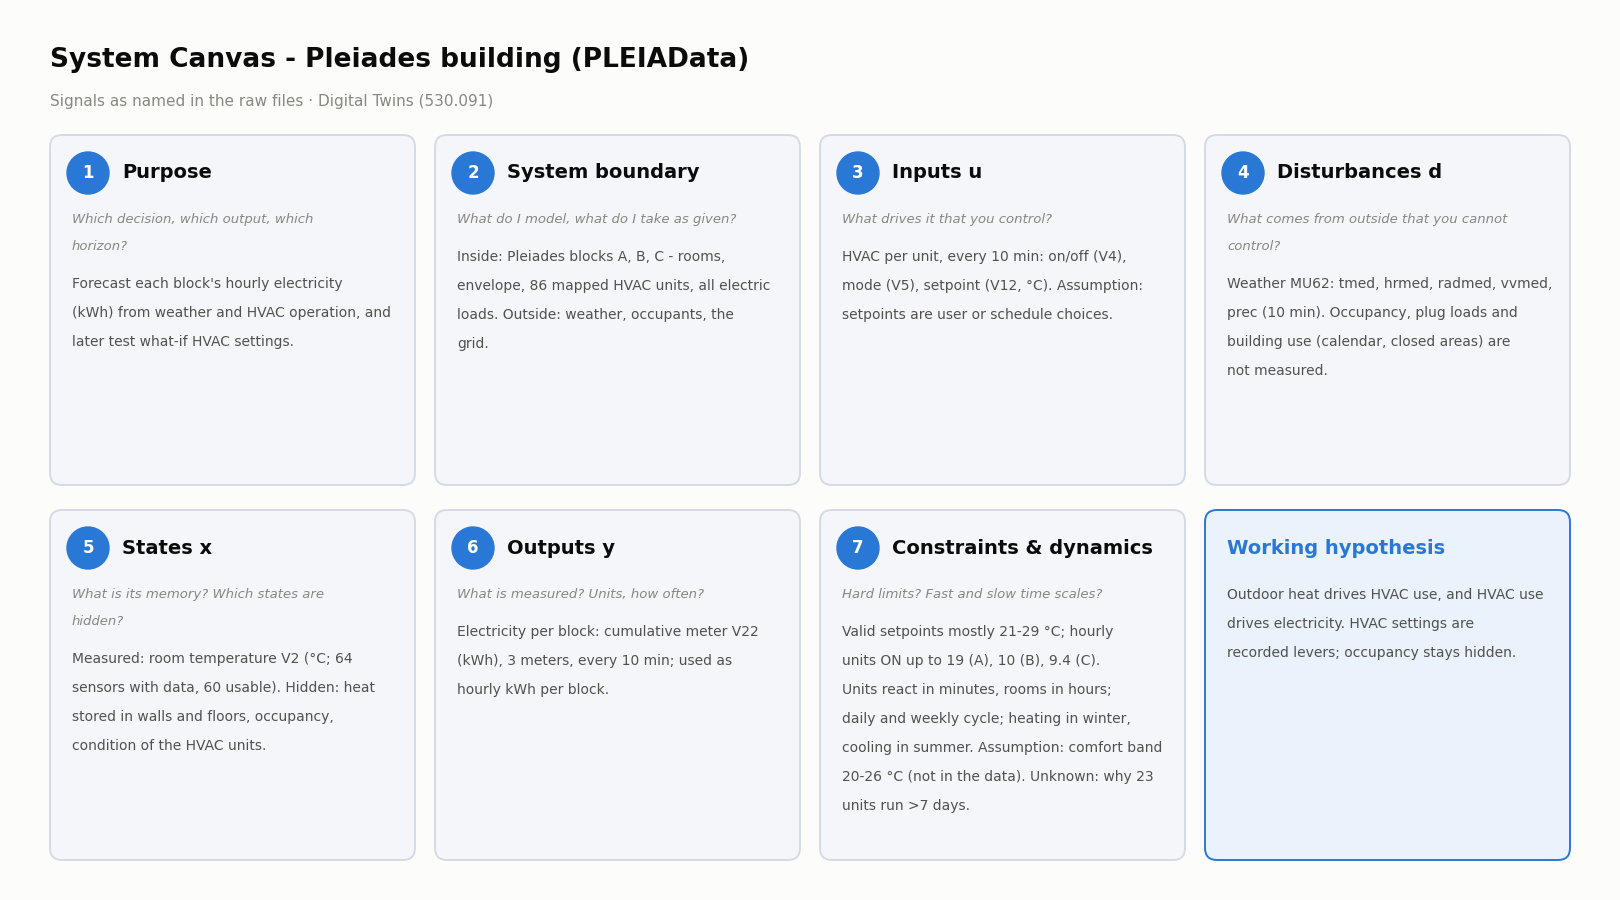

In [6]:
def draw_canvas(boxes, title, subtitle):
    INK, INK2, MUTED, BOX, EDGE, ACC = "#0b0b0b", "#52514e", "#898781", "#f4f6fa", "#d5dbe6", "#2a78d6"
    fig = plt.figure(figsize=(16, 8.8), dpi=100); fig.patch.set_facecolor("white")
    ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, 16); ax.set_ylim(0, 8.8); ax.axis("off")
    ax.text(0.4, 8.3, title, fontsize=19, fontweight="bold", color=INK, va="center")
    ax.text(0.4, 7.88, subtitle, fontsize=11, color=MUTED, va="center")
    w, gap = 3.65, 0.2
    for i, (num, head, sub, body) in enumerate(boxes):
        r, col = divmod(i, 4); x = 0.4 + col * (w + gap); y = 4.05 - r * 3.75; h = 3.5
        lesson = num == ""
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0,rounding_size=0.12",
                                    fc="#eaf2fc" if lesson else BOX, ec=ACC if lesson else EDGE, lw=1.4))
        tx = x + 0.22
        if num:
            ax.add_patch(plt.Circle((x + 0.38, y + h - 0.38), 0.21, color=ACC))
            ax.text(x + 0.38, y + h - 0.38, num, color="white", fontsize=12, fontweight="bold", ha="center", va="center")
            tx = x + 0.72
        ax.text(tx, y + h - 0.38, head, fontsize=14, fontweight="bold", color=ACC if lesson else INK, va="center")
        yy = y + h - 0.78
        for line in textwrap.wrap(sub, 42):
            ax.text(x + 0.22, yy, line, fontsize=9.5, color=MUTED, style="italic", va="top"); yy -= 0.27
        yy -= 0.1 if sub else 0
        for line in textwrap.wrap(body, 44):
            ax.text(x + 0.22, yy, line, fontsize=10, color=INK2, va="top"); yy -= 0.29
    return fig

CANVAS = [
    ("1", "Purpose", "Which decision, which output, which horizon?",
     "Forecast each block's hourly electricity (kWh) from weather and HVAC operation, "
     "and later test what-if HVAC settings."),
    ("2", "System boundary", "What do I model, what do I take as given?",
     "Inside: Pleiades blocks A, B, C - rooms, envelope, 86 mapped HVAC units, all electric loads. "
     "Outside: weather, occupants, the grid."),
    ("3", "Inputs u", "What drives it that you control?",
     "HVAC per unit, every 10 min: on/off (V4), mode (V5), setpoint (V12, °C). "
     "Assumption: setpoints are user or schedule choices."),
    ("4", "Disturbances d", "What comes from outside that you cannot control?",
     "Weather MU62: tmed, hrmed, radmed, vvmed, prec (10 min). Occupancy, plug loads and "
     "building use (calendar, closed areas) are not measured."),
    ("5", "States x", "What is its memory? Which states are hidden?",
     "Measured: room temperature V2 (°C; 64 sensors with data, 60 usable). "
     "Hidden: heat stored in walls and floors, occupancy, condition of the HVAC units."),
    ("6", "Outputs y", "What is measured? Units, how often?",
     "Electricity per block: cumulative meter V22 (kWh), 3 meters, every 10 min; used as hourly kWh per block."),
    ("7", "Constraints & dynamics", "Hard limits? Fast and slow time scales?",
     "Valid setpoints mostly 21-29 °C; hourly units ON up to 19 (A), 10 (B), 9.4 (C). "
     "Units react in minutes, rooms in hours; daily and weekly cycle; heating in winter, cooling in summer. "
     "Assumption: comfort band 20-26 °C (not in the data). Unknown: why 23 units run >7 days."),
    ("", "Working hypothesis", "",
     "Outdoor heat drives HVAC use, and HVAC use drives electricity. HVAC settings are recorded "
     "levers; occupancy stays hidden."),
]
fig = draw_canvas(CANVAS, "System Canvas - Pleiades building (PLEIAData)", "Signals as named in the raw files · Digital Twins (530.091)")
plt.show()

## 2. Cleaning

Each issue follows the same pattern: **what we see → likely cause → what we do.**

### 2.1 Duplicate readings (all files)

In [7]:
dups = pd.DataFrame({
    "exact duplicate rows": [cons_raw.duplicated().sum(), hvac_raw.duplicated().sum(), temp_raw.duplicated().sum(), weather_raw.index.duplicated().sum()],
    "same device and time, different values": [
        cons_raw.duplicated(["IDdevice", "Date"]).sum() - cons_raw.duplicated().sum(),
        hvac_raw.duplicated(["IDdevice", "Date"]).sum() - hvac_raw.duplicated().sum(),
        temp_raw.duplicated(["IDdevice", "Date"]).sum() - temp_raw.duplicated().sum(), 0],
}, index=["electricity", "HVAC", "temperature", "weather"])
cons_raw = cons_raw.drop_duplicates(["IDdevice", "Date"])
hvac_raw = hvac_raw.drop_duplicates(["IDdevice", "Date"])
temp_raw = temp_raw.drop_duplicates(["IDdevice", "Date"])
dups

,exact duplicate rows,"same device and time, different values"
electricity,0,0
HVAC,484,33
temperature,35,0
weather,0,0


* **What we see:** a few hundred repeated HVAC rows and a few dozen repeated temperature rows; the electricity and weather files have none.
* **Likely cause:** the same message stored twice by the logging system.
* **What we do:** keep one row per device and timestamp. The effect is negligible (< 0.02 % of rows).

### 2.2 Logging outages (electricity, HVAC, temperature)

In [8]:
def gaps(dates, min_hours=1):
    t = dates.sort_values().drop_duplicates(); d = t.diff()
    g = d[d > pd.Timedelta(hours=min_hours)]
    return pd.DataFrame({"from (UTC)": (t[g.index] - g).dt.strftime("%d %b %H:%M").values,
                         "to (UTC)": t[g.index].dt.strftime("%d %b %H:%M").values,
                         "hours": (g.dt.total_seconds() / 3600).round(1).values})

out = []
for name, d in [("electricity", cons_raw), ("HVAC", hvac_raw), ("temperature", temp_raw)]:
    g = gaps(d["Date"]); g.insert(0, "log", name); out.append(g)
outages = pd.concat(out, ignore_index=True)
OUTAGES = [(pd.Timestamp("2021-08-12 02:00", tz="UTC"), pd.Timestamp("2021-08-15 23:59", tz="UTC")),
           (pd.Timestamp("2021-12-10 15:00", tz="UTC"), pd.Timestamp("2021-12-13 07:59", tz="UTC"))]
outages

,log,from (UTC),to (UTC),hours
0,electricity,12 Aug 02:16,15 Aug 23:05,92.8
1,electricity,10 Dec 15:16,13 Dec 07:33,64.3
2,HVAC,12 Aug 02:15,15 Aug 23:04,92.8
3,HVAC,10 Dec 15:19,13 Dec 07:22,64.0
4,temperature,12 Aug 02:19,15 Aug 23:04,92.8
5,temperature,10 Dec 15:19,13 Dec 07:22,64.0


* **What we see:** two gaps of **93 h (12–15 Aug)** and **64 h (10–13 Dec)**, at the same time in all three logs. Apart from these, every device reports every 10 minutes.
* **Likely cause:** a failure of the building's data logging system (all devices stop together), not of the equipment.
* **What we do:** the hours inside both gaps become **missing (NaN)**. We do not interpolate: 3–4 days of building operation cannot be reconstructed.

### 2.3 Block C HVAC log gap in May (HVAC)

In [9]:
rel_once = rel_h.drop_duplicates("ID")
hb = hvac_raw.merge(rel_once, left_on="IDdevice", right_on="ID")
rows = []
for b, g in hb.groupby("block"):
    gg = gaps(g["Date"], min_hours=2); gg.insert(0, "block", b); gg.insert(1, "units", g.IDdevice.nunique()); rows.append(gg)
pd.concat(rows, ignore_index=True)

,block,units,from (UTC),to (UTC),hours
0,A,49,12 Aug 02:15,15 Aug 23:04,92.8
1,A,49,10 Dec 15:19,13 Dec 07:22,64.0
2,B,23,12 Aug 02:15,15 Aug 23:04,92.8
3,B,23,10 Dec 15:19,13 Dec 07:22,64.1
4,C,14,01 May 22:04,19 May 08:18,418.2
5,C,14,12 Aug 02:15,15 Aug 23:04,92.8
6,C,14,10 Dec 15:19,13 Dec 07:23,64.1


* **What we see:** besides the two building-wide outages, **all 14 units of block C** stop reporting from **1 to 19 May (418 h)**, while blocks A and B continue.
* **Likely cause:** a communication problem limited to block C's HVAC controllers.
* **What we do:** HVAC values of block C for these hours become **missing**. Block C's electricity is still measured, so we keep it.

### 2.4 Lumped meter readings after the outages (electricity)

In [10]:
lump = []
for b, g in cons_raw.sort_values("Date").groupby("block"):
    d = g["V22"].diff(); dt = g["Date"].diff()
    for i in dt[dt > pd.Timedelta("1h")].index:
        lump.append((b, g.loc[i, "Date"].strftime("%d %b %H:%M"), round(d[i], 1)))
lump = pd.DataFrame(lump, columns=["block", "first reading after gap (UTC)", "kWh in that single step"])
print("Meter ever decreasing:", any((g.sort_values("Date")["V22"].diff() < 0).any() for _, g in cons_raw.groupby("block")))
lump

Meter ever decreasing: False


,block,first reading after gap (UTC),kWh in that single step
0,A,15 Aug 23:05,712.5
1,A,13 Dec 07:33,135.4
2,B,15 Aug 23:05,326.5
3,B,13 Dec 07:33,246.0
4,C,15 Aug 23:05,576.6
5,C,13 Dec 07:33,43.2


* **What we see:** the first reading after each outage jumps by up to several hundred kWh in one 10-min step, compared with about 0.2–2 kWh in a normal step. The meters never count backwards.
* **Likely cause:** the meter kept counting during the outage; the whole gap's energy appears in one step.
* **What we do:** when we convert the meter to hourly energy (Section 3), we never take a difference across a gap. The lumped step therefore does not enter the data as a fake spike.

### 2.5 High electricity values: real peaks, not outliers (electricity)

The dataset authors removed every hour with 0 kWh or ≥ 25 kWh to get rid of the outage artifacts. We check what such a fixed cut-off would remove from correctly computed hourly data.

In [11]:
def hourly_energy(cons, start="2021-01-01", end="2022-01-01"):
    grid = pd.date_range(start, end, freq="h", tz="UTC")
    out = {}
    for b, g in cons.groupby("block"):
        s = g.set_index("Date")["V22"].sort_index()
        u = s.reindex(s.index.union(grid)).interpolate("time", limit_area="inside")
        step = s.index.to_series().diff()
        for end_, d in step[step > pd.Timedelta("1h")].items():
            u[(u.index > end_ - d) & (u.index < end_)] = np.nan          # never bridge a logging gap
        out[b] = u.reindex(grid).diff().shift(-1)                         # kWh in the hour starting at t
    return pd.DataFrame(out).iloc[:-1]

energy = hourly_energy(cons_raw)
check = pd.DataFrame({
    "hours >= 25 kWh": (energy >= 25).sum(),
    "max hourly kWh": energy.max().round(1),
    "hours with exactly 0 kWh": (energy == 0).sum(),
    "of these in Jun-Sep": energy[energy.index.month.isin([6, 7, 8, 9])].ge(25).sum(),
})
check

,hours >= 25 kWh,max hourly kWh,hours with exactly 0 kWh,of these in Jun-Sep
A,2,27.6,0,2
B,0,13.8,0,0
C,301,48.1,0,244


* **What we see:** outside the outages there are **no 0 kWh hours**. Block C has about 300 hours ≥ 25 kWh (up to 48 kWh), most of them in June–September; block A reaches 25 kWh only twice; B never does.
* **Likely cause:** block C's cooling load on hot days. These are real values.
* **What we do:** we **keep** them. A fixed 25 kWh cut-off would delete exactly the peak cooling hours our model must learn. The outage artifacts are already handled in 2.2 and 2.4.

### 2.6 HVAC units missing from the room list (HVAC)

In [12]:
unmapped = sorted(set(hvac_raw.IDdevice) - set(rel_h.ID))
double = rel_h[rel_h.ID.duplicated(keep=False)]
print("Units in the log but not in relations-hvac.csv:", unmapped, f"({hvac_raw.IDdevice.isin(unmapped).mean():.1%} of rows)")
print("Units listed in more than one room:"); print(double.to_string(index=False))
hvac_raw = hvac_raw[~hvac_raw.IDdevice.isin(unmapped)].merge(
    rel_h.drop_duplicates("ID").rename(columns={"ID": "IDdevice"}), on="IDdevice", how="left")
print(f"\nHVAC units kept: {hvac_raw.IDdevice.nunique()}  ->", hvac_raw.groupby('block').IDdevice.nunique().to_dict())

Units in the log but not in relations-hvac.csv: [335545145, 335545195] (2.3% of rows)
Units listed in more than one room:
       ID block  room
335545193     C    19
335545193     C    20

HVAC units kept: 86  -> {'A': 49, 'B': 23, 'C': 14}


* **What we see:** 2 units appear in the log but not in the room list; 1 unit is listed for two rooms (C19 and C20).
* **Likely cause:** incomplete device registry; the double entry is probably one unit serving two adjacent rooms.
* **What we do:** we **drop the 2 unmapped units** (their block is unknown). The double entry does not matter at block level (both rooms are in C); we keep the unit once.

### 2.7 Invalid setpoints (HVAC)

Setpoints outside 10–35 °C: 547,151 rows (12.9%)
  of these exactly 0 °C: 547,006   | negative: 132   | above 35 °C: 13
  share while the unit is ON: 21%
Most common valid setpoints (°C): {21.0: 1102204, 22.0: 723007, 23.0: 535447, 24.0: 402555, 25.0: 346938, 26.0: 207159, 27.0: 192541, 29.0: 140435}


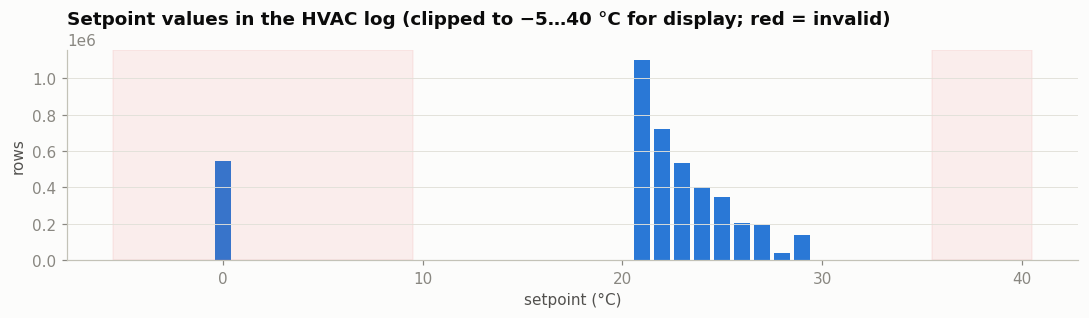

In [13]:
sp = hvac_raw["V12"]
invalid = (sp < 10) | (sp > 35)
print(f"Setpoints outside 10–35 °C: {invalid.sum():,} rows ({invalid.mean():.1%})")
print(f"  of these exactly 0 °C: {(sp == 0).sum():,}   | negative: {(sp < 0).sum()}   | above 35 °C: {(sp > 35).sum()}")
print(f"  share while the unit is ON: {hvac_raw.loc[invalid, 'V4'].mean():.0%}")
print("Most common valid setpoints (°C):", sp[~invalid].value_counts().head(8).to_dict())
fig, ax = plt.subplots(figsize=(10, 3))
vals = sp.clip(-5, 40).round()
ax.bar(vals.value_counts().sort_index().index, vals.value_counts().sort_index().values, color=C["blue"], width=0.8)
ax.axvspan(-5.5, 9.5, color=C["red"], alpha=0.08); ax.axvspan(35.5, 40.5, color=C["red"], alpha=0.08)
ax.set_title("Setpoint values in the HVAC log (clipped to −5…40 °C for display; red = invalid)")
ax.set_xlabel("setpoint (°C)"); ax.set_ylabel("rows"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
hvac_raw.loc[invalid, "V12"] = np.nan

* **What we see:** about **13 %** of setpoint values are outside 10–35 °C. Almost all of them are **exactly 0 °C**; a few dozen are around −30 °C or above 60 °C. Valid setpoints cluster at 21–29 °C.
* **Likely cause:** 0 is a placeholder when the unit reports no setpoint; the extreme values are transmission errors.
* **What we do:** set them to **missing**. We do not forward-fill them (as the authors did), because that would invent a setting the user never chose.

### 2.8 Rare HVAC modes 'dry' and 'fan' (HVAC)

In [14]:
mode_counts = hvac_raw["V5"].value_counts().sort_index()
mode_counts.index = mode_counts.index.map({0: "0 none", 1: "1 heating", 2: "2 cooling", 3: "3 dry", 4: "4 fan"})
pd.DataFrame({"rows": mode_counts, "share": (mode_counts / mode_counts.sum()).round(4)})

,rows,share
V5,,
0 none,114343,0.0270
1 heating,1469440,0.3465
2 cooling,2644071,0.6235
3 dry,11635,0.0027
4 fan,864,0.0002


* **What we see:** modes 3 (dry) and 4 (fan) together are well below 1 % of rows.
* **Likely cause:** rarely used operating modes, not errors.
* **What we do:** keep them, but count only **heating** and **cooling** as separate operating states in the preparation; dry and fan stay inside "units ON".

### 2.9 Units ON for a long time without interruption (HVAC)

In [15]:
long_on = []
for dev, g in hvac_raw.sort_values(["IDdevice", "Date"]).groupby("IDdevice"):
    r = (g["V4"] != g["V4"].shift()).cumsum()
    seg = g.groupby(r).agg(on=("V4", "first"), t0=("Date", "min"), t1=("Date", "max"))
    seg["days"] = (seg.t1 - seg.t0).dt.total_seconds() / 86400
    seg = seg[(seg.on == 1) & (seg.days > 7)]
    if len(seg): long_on.append((dev, g["block"].iloc[0], g["room"].iloc[0], len(seg), round(seg.days.max(), 1)))
long_on = pd.DataFrame(long_on, columns=["unit", "block", "room", "periods > 7 days ON", "longest (days)"]).sort_values("longest (days)", ascending=False)
print(f"Units ON for more than 7 days in a row at least once: {len(long_on)} of {hvac_raw.IDdevice.nunique()}")
long_on.head(10)

Units ON for more than 7 days in a row at least once: 23 of 86


,unit,block,room,periods > 7 days ON,longest (days)
12,335545275,A,63,3,206.6
1,335545143,B,2,4,197.4
2,335545147,B,1,4,197.3
3,335545149,B,1,4,197.3
11,335545269,A,58,2,194.4
10,335545267,A,57,2,194.4
15,335545287,A,66,5,175.1
14,335545285,A,65,4,120.1
8,335545227,A,42,3,89.0
17,335545291,A,69,2,76.1


* **What we see:** 23 units stay ON for more than a week without a single OFF reading; some run for **half a year** (e.g. A63, and B1–B2 for about 197 days). Because of them, blocks A and B never have zero units ON.
* **Likely cause:** units deliberately left running, most likely rooms with equipment that needs constant cooling. The log has no gaps here, so it is not missing data.
* **What we do:** **keep** them – it is real operation and real energy use. They form a permanent HVAC base load in A and B.

### 2.10 Temperature sensors without data or not in the room list (temperature)

In [16]:
with_data = set(temp_raw.IDdevice)
print(f"Device IDs in data-sensor.csv: {len(ids_in_file)}   | listed in relations-sensor.csv: {rel_s.ID.nunique()}")
print(f"Listed sensors WITH data: {len(with_data)}   | listed sensors WITHOUT any reading: {rel_s.ID.nunique() - len(with_data)}")
print("Sensors with data per block:", temp_raw.groupby("block").IDdevice.nunique().to_dict())

Device IDs in data-sensor.csv: 191   | listed in relations-sensor.csv: 90
Listed sensors WITH data: 64   | listed sensors WITHOUT any reading: 26
Sensors with data per block: {'A': 41, 'B': 17, 'C': 6}


* **What we see:** the file contains many more device IDs than temperature sensors, and only part of the listed sensors ever report.
* **Likely cause:** `data-sensor.csv` also holds other device types; some listed sensors were never connected or never sent data.
* **What we do:** use only listed sensors with data. Each block still has several sensors.

### 2.11 Broken temperature sensors (temperature)

In [17]:
share_ok = temp_raw.assign(ok=temp_raw["V2"].between(10, 40)).groupby(["IDdevice", "block", "room"]).ok.mean().reset_index()
broken = share_ok[share_ok.ok < 0.5]
examples = temp_raw[temp_raw.IDdevice.isin(broken.IDdevice)].groupby("IDdevice")["V2"].agg(lambda s: s.iloc[0])
broken = broken.assign(**{"share of readings in 10–40 °C": broken.ok.round(3), "example value": broken.IDdevice.map(examples)}).drop(columns="ok")
print(f"Rows from these sensors: {temp_raw.IDdevice.isin(broken.IDdevice).sum():,} ({temp_raw.IDdevice.isin(broken.IDdevice).mean():.1%} of temperature rows)")
temp_raw = temp_raw[~temp_raw.IDdevice.isin(broken.IDdevice)]
broken

Rows from these sensors: 206,467 (6.3% of temperature rows)


,IDdevice,block,room,share of readings in 10–40 °C,example value
44,335544823,B,84,0.0,5.593909e+64
49,335544863,B,85,0.0,-4.648804e-07
57,335545055,B,86,0.0,1.616377e-115
58,335545056,B,86,0.0,-1.487516e-193


* **What we see:** 4 sensors (block B, rooms 84–86) **never** report a value between 10 and 40 °C; their values are numbers like 10⁻¹¹⁵ or 10⁶⁴.
* **Likely cause:** faulty sensors or a wrong data encoding for these devices.
* **What we do:** **remove these 4 sensors** completely. No reading of them is usable.

### 2.12 Cold readings below 10 °C in working sensors (temperature)

In [18]:
low = temp_raw[temp_raw["V2"] < 10]
hi = temp_raw[temp_raw["V2"] > 40]
print(f"Readings < 10 °C: {len(low)} ({len(low)/len(temp_raw):.3%})  | readings > 40 °C: {len(hi)}")
low.assign(month=low.Date.dt.month).groupby(["IDdevice", "block", "room"]).agg(
    readings=("V2", "size"), min_C=("V2", "min"), months=("month", lambda m: sorted(m.unique()))).reset_index()

Readings < 10 °C: 202 (0.007%)  | readings > 40 °C: 0


,IDdevice,block,room,readings,min_C,months
0,335544685,B,14,11,8.641659,[1]
1,335544792,A,41,154,7.987427,[1]
2,335544857,B,11,37,8.716732,[1]


* **What we see:** about 200 readings between 8 and 10 °C in three sensors, all in January; nothing above 40 °C.
* **Likely cause:** unheated rooms on cold winter nights – physically plausible.
* **What we do:** **keep** them.

### 2.13 Weather gaps (weather)

In [19]:
w21 = weather_raw.loc["2021"]
g = gaps(w21.index.to_series()); g.insert(0, "log", "weather")
print(f"Last reading of 2021: {w21.index.max():%d %b %H:%M}   | next reading: {weather_raw.loc['2022'].index.min():%d %b %Y}")
print(f"Readings in 2021: {len(w21):,} of {365*144:,} possible ({len(w21)/(365*144):.1%})")
print("Timestamp steps:", {f"{int(k.total_seconds()/60)} min": int(v) for k, v in w21.index.to_series().diff().value_counts().head(3).items()})
g

Last reading of 2021: 18 Dec 13:30   | next reading: 10 Jan 2022
Readings in 2021: 49,773 of 52,560 possible (94.7%)
Timestamp steps: {'10 min': 49081, '8 min': 345, '12 min': 345}


,log,from (UTC),to (UTC),hours
0,weather,12 Oct 02:00,18 Oct 00:10,142.2


* **What we see:** one gap of about 6 days (12–18 Oct), and **no weather after 18 Dec 13:30** for the rest of the year. Some timestamps are 8 or 12 min apart instead of 10.
* **Likely cause:** station downtime; small clock jitter of the logger.
* **What we do:** the gaps stay **missing**; we only interpolate gaps of up to 2 hours after aggregation. The jitter disappears when we average per hour.

### 2.14 Weather plausibility (weather)

In [20]:
limits = {"tmed": (-15, 50), "hrmed": (0, 100), "radmed": (0, 1400), "vvmed": (0, 40), "dvmed": (0, 360), "prec": (0, 200)}
pd.DataFrame({c: {"min": w21[c].min(), "max": w21[c].max(), "outside physical range": int(((w21[c] < lo) | (w21[c] > hi)).sum())}
              for c, (lo, hi) in limits.items()}).T

,min,max,outside physical range
tmed,-2.2,45.9,0.0
hrmed,4.2,94.1,0.0
radmed,0.0,1172.0,0.0
vvmed,0.0,4.4,0.0
dvmed,0.0,360.0,0.0
prec,0.0,9.0,0.0


* **What we see:** all values are within physical limits. The maximum of 45.9 °C (15 Aug) falls in the August 2021 heat wave in Spain.
* **What we do:** nothing – no weather outliers.

### 2.15 Cleaning summary

In [21]:
sp_share = hvac_raw["V12"].isna().mean()
pd.DataFrame([
    ("Duplicate readings",               "all logs",    "< 0.02 % of rows",                    "logging duplicates",          "keep one row per device and time"),
    ("Logging outages",                  "elec, HVAC, temp", "93 h + 64 h, all devices",        "logging system down",         "hours set to missing, no interpolation"),
    ("Block C HVAC log gap",             "HVAC",        "1–19 May, 418 h, 14 units",           "block-level communication",   "hours set to missing (block C HVAC only)"),
    ("Lumped meter step after outage",   "electricity", "2 per meter",                          "meter counted during outage", "never difference across a gap"),
    ("Hours >= 25 kWh",                  "electricity", f"{int(check.loc['C', 'hours >= 25 kWh'])} h in block C",                    "real summer cooling peaks",   "keep (no fixed cut-off)"),
    ("Units not in room list",           "HVAC",        "2 units",                              "incomplete registry",         "drop"),
    ("Invalid setpoints (mostly 0 °C)",  "HVAC",        f"{sp_share:.1%} of rows",                       "placeholder / errors",        "set to missing, no forward fill"),
    ("Modes dry / fan",                  "HVAC",        "< 1 % of rows",                        "rare real modes",             "keep, counted as ON only"),
    ("Units ON > 7 days",                "HVAC",        f"{len(long_on)} units",                "units left running",          "keep (real operation)"),
    ("Sensors without data / unlisted",  "temperature", "26 listed sensors without data",       "registry / other devices",    "use listed sensors with data"),
    ("Broken sensors",                   "temperature", "4 sensors (B84–86)",                   "faulty sensor / encoding",    "remove"),
    ("Readings < 10 °C",                 "temperature", f"{len(low)} readings, January",                "cold unheated rooms",         "keep"),
    ("Station gaps",                     "weather",     "12–18 Oct, 18–31 Dec",                 "station downtime",            "missing; interpolate only ≤ 2 h"),
], columns=["issue", "signal", "amount", "likely cause", "action"])

,issue,signal,amount,likely cause,action
0,Duplicate readings,all logs,< 0.02 % of rows,logging duplicates,keep one row per device and time
1,Logging outages,"elec, HVAC, temp","93 h + 64 h, all devices",logging system down,"hours set to missing, no interpolation"
2,Block C HVAC log gap,HVAC,"1–19 May, 418 h, 14 units",block-level communication,hours set to missing (block C HVAC only)
3,Lumped meter step after outage,electricity,2 per meter,meter counted during outage,never difference across a gap
4,Hours >= 25 kWh,electricity,301 h in block C,real summer cooling peaks,keep (no fixed cut-off)
5,Units not in room list,HVAC,2 units,incomplete registry,drop
6,Invalid setpoints (mostly 0 °C),HVAC,12.9% of rows,placeholder / errors,"set to missing, no forward fill"
7,Modes dry / fan,HVAC,< 1 % of rows,rare real modes,"keep, counted as ON only"
8,Units ON > 7 days,HVAC,23 units,units left running,keep (real operation)
9,Sensors without data / unlisted,temperature,26 listed sensors without data,registry / other devices,use listed sensors with data


## 3. Preparation

| Step | Applied? | What and why |
|---|---|---|
| **Time alignment** | yes | All logs → one **hourly UTC grid**. The sources report at different moments; a common grid lets us compare them hour by hour. For daily routines we add **local time** (Europe/Madrid). |
| **Aggregation** | yes | 10 min → **1 hour**, and devices → **blocks**. The objective is hourly energy per block; hourly values also smooth logging jitter. |
| **Encoding** | yes | Calendar features (hour, weekday, weekend, month); HVAC modes as **counts of units heating / cooling**. Turns categories into numbers that can be plotted and modelled. |
| **Scaling** | no | The EDA reads best in physical units (kWh, °C). Scaling depends on the model and will be fitted on the training period only, to avoid leakage. |

### 3.1 Electricity → hourly kWh per block

In [22]:
energy["total"] = energy[BLOCKS].sum(axis=1, min_count=3)
print(f"Hourly grid: {len(energy):,} hours | missing: {energy['total'].isna().sum()} h ({energy['total'].isna().mean():.1%}) – the two outages")
energy.describe().round(2)

Hourly grid: 8,760 hours | missing: 161 h (1.8%) – the two outages


,A,B,C,total
count,8599.00,8599.00,8599.00,8599.00
mean,4.76,2.67,4.87,12.30
std,3.01,1.88,6.79,9.54
min,0.02,0.07,0.00,0.09
25%,2.41,0.81,0.67,6.54
50%,4.13,2.70,2.52,8.91
75%,6.52,3.59,5.21,13.69
max,27.64,13.85,48.10,79.43


The meter is cumulative, so the energy of an hour is the meter at the end minus the meter at the start (interpolated to the full hour). Hours inside an outage stay missing.

### 3.2 HVAC → units ON, heating, cooling and setpoint per block and hour

In [23]:
h = hvac_raw.copy()
h["hour"] = h["Date"].dt.floor("h")
h["heat"] = (h["V4"] == 1) & (h["V5"] == 1)
h["cool"] = (h["V4"] == 1) & (h["V5"] == 2)
h["sp_on"] = h["V12"].where(h["V4"] == 1)          # a setpoint only matters while the unit runs
per_unit = h.groupby(["block", "IDdevice", "hour"]).agg(on=("V4", "mean"), heat=("heat", "mean"), cool=("cool", "mean"), sp=("sp_on", "mean"))
per_block = per_unit.groupby(["block", "hour"]).agg(units_on=("on", "sum"), units_heat=("heat", "sum"),
                                                     units_cool=("cool", "sum"), setpoint_on=("sp", "mean"))
hvac_h = per_block.unstack("block")
hvac_h.columns = [f"{a}_{b}" for a, b in hvac_h.columns]
hvac_h = hvac_h.reindex(energy.index)              # hours without any log entry (outages) stay missing
hvac_h.describe().round(2)

,units_on_A,units_on_B,units_on_C,units_heat_A,units_heat_B,units_heat_C,units_cool_A,units_cool_B,units_cool_C,setpoint_on_A,setpoint_on_B,setpoint_on_C
count,8604.00,8604.00,8187.00,8604.00,8604.00,8187.00,8604.00,8604.00,8187.00,8604.00,8604.00,2193.00
mean,6.75,3.52,0.55,0.82,0.45,0.29,5.94,3.06,0.22,23.23,22.57,25.30
std,3.29,1.14,1.25,1.30,0.70,0.99,3.94,1.26,0.78,1.14,0.48,1.28
min,1.00,1.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,21.00,22.00,21.00
25%,4.00,3.00,0.00,0.00,0.00,0.00,2.00,2.00,0.00,22.50,22.33,24.33
50%,8.00,3.00,0.00,0.00,0.00,0.00,7.00,3.00,0.00,23.33,22.33,25.00
75%,9.00,4.00,0.43,1.00,1.00,0.00,9.00,4.00,0.00,23.60,22.50,26.00
max,19.00,10.00,9.43,7.00,4.71,9.43,19.00,10.00,7.43,27.25,25.69,29.00


* `units_on` = number of units running in that hour (a unit ON for 30 min counts 0.5).
* `units_heat` / `units_cool` = the same, split by mode.
* `setpoint_on` = mean setpoint of the units that are ON (missing when no unit runs).
* Block C's HVAC columns are missing for 1–19 May (Section 2.3). In A and B at least one unit is always ON (Section 2.9).

### 3.3 Temperature → mean room temperature per block and hour

In [24]:
t = temp_raw.assign(hour=temp_raw["Date"].dt.floor("h"))
tin = t.groupby(["block", "IDdevice", "hour"])["V2"].mean().groupby(["block", "hour"]).mean().unstack("block")
tin.columns = [f"tin_{b}" for b in tin.columns]
tin = tin.reindex(energy.index)
tin.describe().round(2)

,tin_A,tin_B,tin_C
count,8604.00,8604.00,8604.00
mean,27.27,26.39,26.58
std,3.47,4.26,2.72
min,19.18,16.09,20.24
25%,24.57,23.05,24.28
50%,26.47,25.60,26.16
75%,30.50,30.57,29.21
max,33.93,33.69,31.83


### 3.4 Weather → hourly means

In [25]:
wx = weather_raw[["tmed", "hrmed", "radmed", "vvmed", "prec"]].resample("h").mean().reindex(energy.index)
before = wx["tmed"].isna().sum()
wx = wx.interpolate(limit=2, limit_area="inside")
print(f"Missing weather hours: {before} before, {wx['tmed'].isna().sum()} after interpolating gaps of up to 2 h")

Missing weather hours: 463 before, 461 after interpolating gaps of up to 2 h


### 3.5 Calendar encoding and final table

In [26]:
df = pd.concat([energy.add_prefix("kwh_"), hvac_h, tin, wx], axis=1)
local = df.index.tz_convert(TZ)
df["hour_local"], df["weekday"] = local.hour, local.dayofweek
df["weekend"] = (local.dayofweek >= 5).astype(int)
df["month"] = local.month
df.index.name = "time_utc"

os.makedirs(OUT, exist_ok=True)
df.to_csv(OUT + "pleiadata_hourly.csv")
print(f"Prepared table: {df.shape[0]:,} hours × {df.shape[1]} columns  ->  saved to {OUT}pleiadata_hourly.csv")
miss = (df.isna().mean() * 100).round(1).rename("% missing").to_frame()
miss.T

Prepared table: 8,760 hours × 28 columns  ->  saved to ../Data/prepared/pleiadata_hourly.csv


,kwh_A,kwh_B,kwh_C,kwh_total,units_on_A,units_on_B,units_on_C,units_heat_A,units_heat_B,units_heat_C,units_cool_A,units_cool_B,units_cool_C,setpoint_on_A,setpoint_on_B,setpoint_on_C,tin_A,tin_B,tin_C,tmed,hrmed,radmed,vvmed,prec,hour_local,weekday,weekend,month
% missing,1.8,1.8,1.8,1.8,1.8,1.8,6.5,1.8,1.8,6.5,1.8,1.8,6.5,1.8,1.8,75.0,1.8,1.8,1.8,5.3,5.3,5.3,5.3,5.3,0.0,0.0,0.0,0.0


Remaining missing values come from the two logging outages (all building signals) and the weather station gaps. Hours with no unit running have no `setpoint_on` by design.

## 4. Exploratory Data Analysis

### 4.1 Patterns of missing data

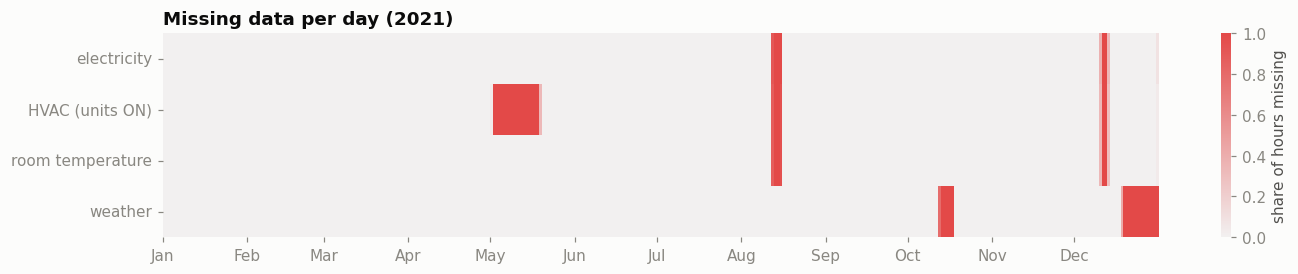

In [27]:
groups = {"electricity": [f"kwh_{b}" for b in BLOCKS], "HVAC (units ON)": [f"units_on_{b}" for b in BLOCKS],
          "room temperature": [f"tin_{b}" for b in BLOCKS], "weather": ["tmed", "radmed", "hrmed"]}
daily_miss = pd.DataFrame({g: df[cols].isna().any(axis=1).resample("D").mean() for g, cols in groups.items()}).T
fig, ax = plt.subplots(figsize=(13, 2.6))
sns.heatmap(daily_miss, cmap=sns.light_palette(C["red"], as_cmap=True), vmin=0, vmax=1, cbar_kws={"label": "share of hours missing"}, ax=ax)
ax.set_xticks([daily_miss.columns.get_loc(d) for d in daily_miss.columns if d.day == 1])
ax.set_xticklabels([MONTHS[d.month - 1] for d in daily_miss.columns if d.day == 1], rotation=0)
ax.set_xlabel(""); ax.set_title("Missing data per day (2021)"); ax.grid(False)
plt.tight_layout(); plt.show()

**Finding:** missing data comes in a few long blocks, not scattered: the two logging outages hit all building signals at once, block C's HVAC is missing for 1–19 May, and the weather for 12–18 Oct and after 18 Dec. **Consequence:** we model **1 Jan – 17 Dec**, exclude these hours instead of imputing them, and keep in mind that block C has no HVAC information for most of May.

### 4.2 Time series: electricity per block and outdoor temperature

Electricity 2021 (MWh, without outage hours): {'kwh_A': 41.0, 'kwh_B': 22.9, 'kwh_C': 41.9}


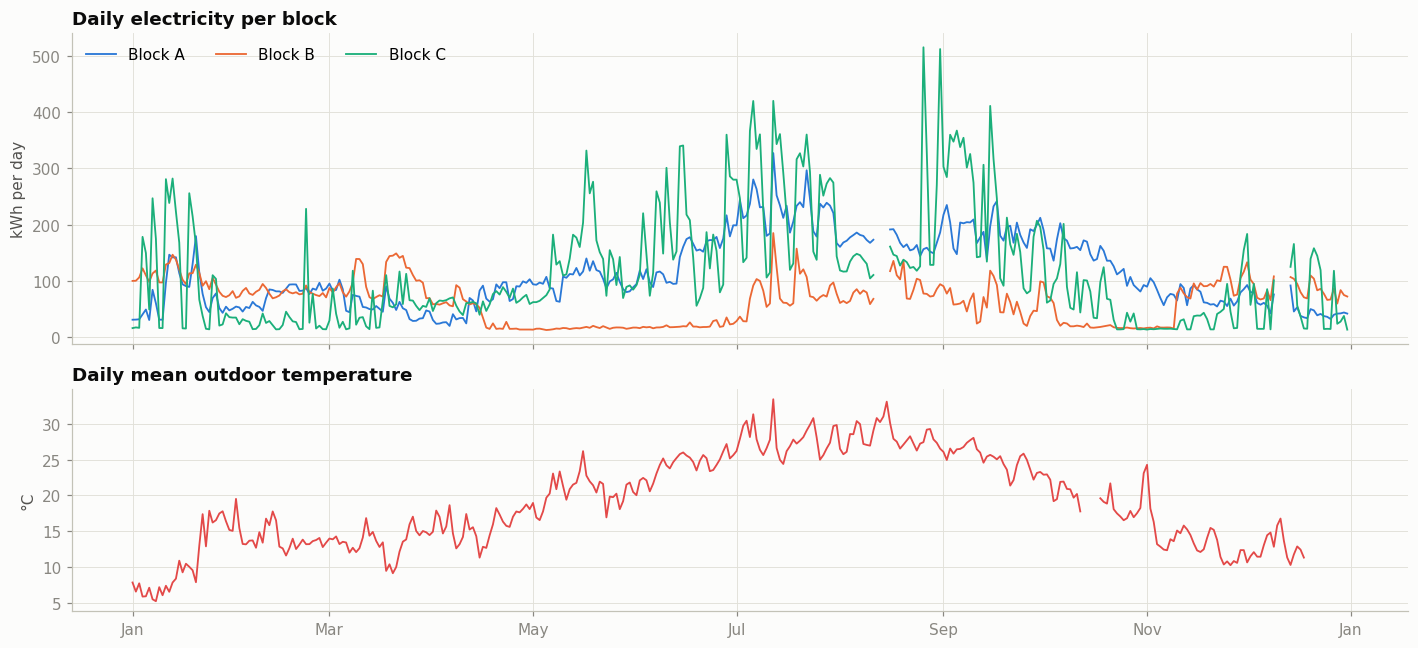

In [28]:
daily = df[[f"kwh_{b}" for b in BLOCKS]].resample("D").sum(min_count=20)
fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True, gridspec_kw={"height_ratios": [1.4, 1]})
for b in BLOCKS:
    ax[0].plot(daily.index, daily[f"kwh_{b}"], color=BCOL[b], lw=1.2, label=f"Block {b}")
ax[0].set_ylabel("kWh per day"); ax[0].set_title("Daily electricity per block"); ax[0].legend(loc="upper left", ncol=3)
ax[1].plot(df["tmed"].resample("D").mean(), color=C["red"], lw=1.2)
ax[1].set_ylabel("°C"); ax[1].set_title("Daily mean outdoor temperature")
ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
plt.tight_layout(); plt.show()
print("Electricity 2021 (MWh, without outage hours):", (df[[f'kwh_{b}' for b in BLOCKS]].sum() / 1000).round(1).to_dict())

**Finding:** blocks A and C follow the outdoor temperature – highest in summer (cooling) with a smaller winter bump (heating). Block B works on two levels: about 15–20 kWh/day from mid-April to early July (and in parts of October–November), and 50–150 kWh/day otherwise. The dip in mid-August fits the university's summer closure. **Consequence:** the blocks behave differently, so we model them **separately**; use of the building (calendar, closed areas) is a driver the data does not record.

### 4.3 Distribution and statistics per operating condition

Season split follows the dominant HVAC mode in the log (heating Nov–Apr, cooling May–Oct).


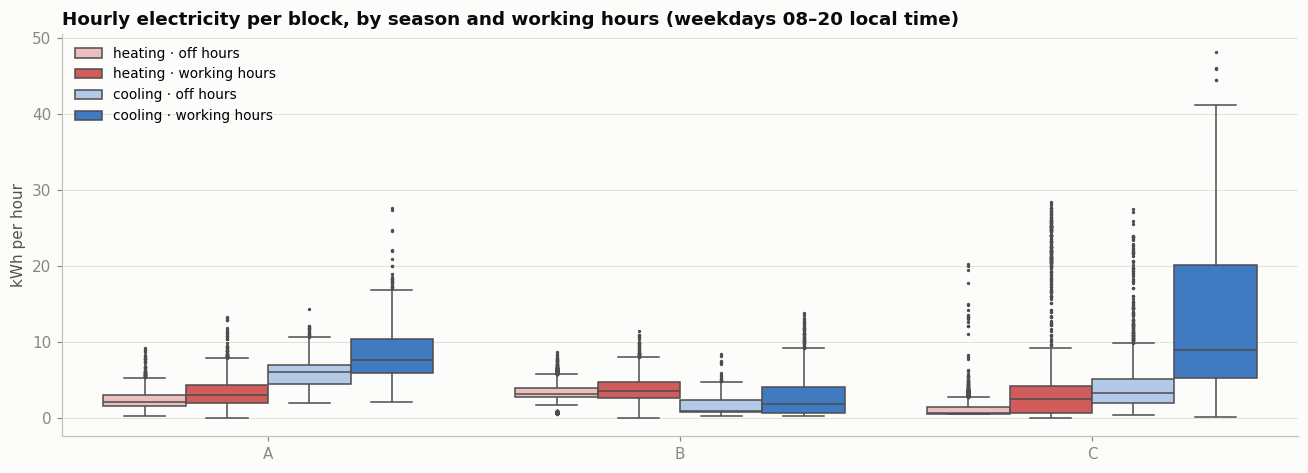

count  mean  50%   95%   max
A heating · off hours      2709.0   2.4  2.1   4.3   9.2
  heating · working hours  1567.0   3.4  3.1   7.2  13.3
  cooling · off hours      2787.0   5.8  6.0   8.4  14.3
  cooling · working hours  1536.0   8.4  7.7  15.1  27.6
B heating · off hours      2709.0   3.2  3.1   5.7   8.7
  heating · working hours  1567.0   3.7  3.5   7.1  11.5
  cooling · off hours      2787.0   1.5  0.9   3.5   8.5
  cooling · working hours  1536.0   2.8  1.9   7.9  13.8
C heating · off hours      2709.0   1.2  0.7   3.5  20.3
  heating · working hours  1567.0   4.7  2.5  22.7  28.5
  cooling · off hours      2787.0   4.0  3.3   9.7  27.4
  cooling · working hours  1536.0  13.0  9.0  31.9  48.1

In [29]:
lt = df.index.tz_convert(TZ)
season = np.where(lt.month.isin([5, 6, 7, 8, 9, 10]), "cooling season (May–Oct)", "heating season (Nov–Apr)")
work = np.where((lt.dayofweek < 5) & (lt.hour >= 8) & (lt.hour < 20), "working hours", "off hours")
long = pd.concat([pd.DataFrame({"block": b, "kWh": df[f"kwh_{b}"].values, "season": season, "time": work}) for b in BLOCKS]).dropna()
long["condition"] = long["season"].str.split(" ").str[0] + " · " + long["time"]
order = ["heating · off hours", "heating · working hours", "cooling · off hours", "cooling · working hours"]
pal = dict(zip(order, ["#f2b8b5", C["red"], "#a9c8f0", C["blue"]]))
fig, ax = plt.subplots(figsize=(12, 4.4))
sns.boxplot(data=long, x="block", y="kWh", hue="condition", hue_order=order, palette=pal, fliersize=1.2, linewidth=1, ax=ax)
ax.set_title("Hourly electricity per block, by season and working hours (weekdays 08–20 local time)")
ax.set_ylabel("kWh per hour"); ax.set_xlabel(""); ax.legend(title="", loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()
print("Season split follows the dominant HVAC mode in the log (heating Nov–Apr, cooling May–Oct).")
stats = long.groupby(["block", "condition"])["kWh"].describe(percentiles=[.5, .95])[["count", "mean", "50%", "95%", "max"]].round(1)
stats.reindex(pd.MultiIndex.from_product([BLOCKS, order]))

**Finding:** hourly electricity is right-skewed in every block. Working hours use clearly more than off hours, and the gap is largest in the cooling season, especially in block C, whose cooling-season working hours reach up to 48 kWh. Block B is the exception: it uses more in the heating season. **Consequence:** season and working hours define the main operating conditions; error metrics should be robust to the skew (e.g. MAE).

### 4.4 Relationship: daily electricity vs. outdoor temperature

Spearman correlation with hourly electricity:


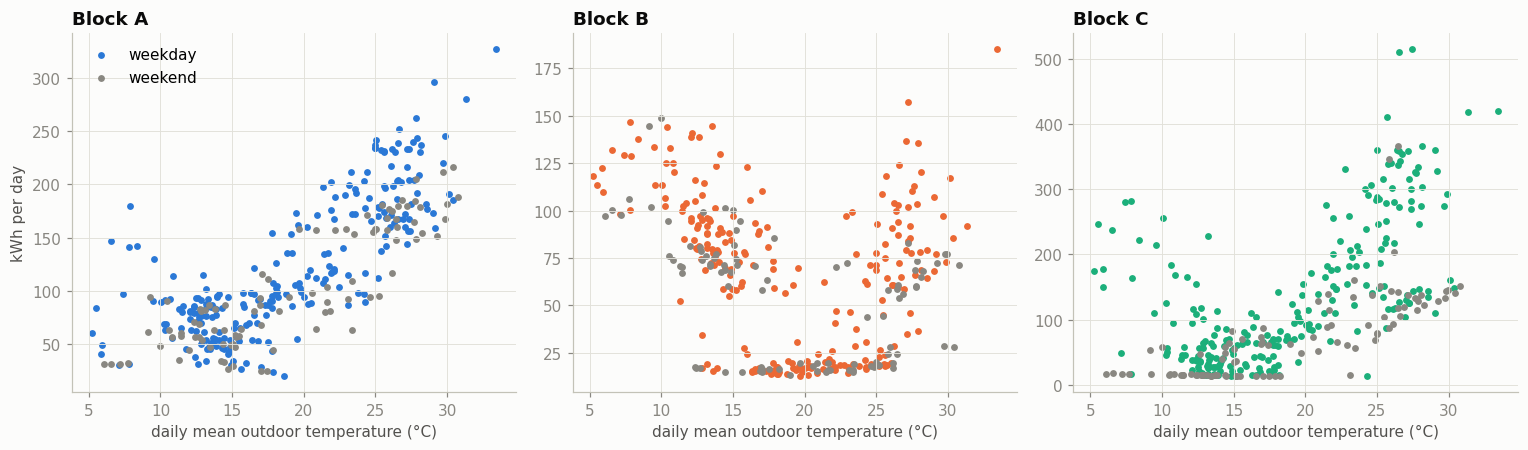

,A,B,C
outdoor temperature,0.70,-0.25,0.64
solar radiation,0.32,0.01,0.51
units ON,0.66,0.52,0.41
room temperature,0.74,-0.31,0.52


In [30]:
d = pd.DataFrame({b: df[f"kwh_{b}"].resample("D").sum(min_count=20) for b in BLOCKS})
d["T"] = df["tmed"].resample("D").mean()
d["weekend"] = d.index.tz_convert(TZ).dayofweek >= 5
d = d.dropna()
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2), sharex=True)
for a, b in zip(ax, BLOCKS):
    a.scatter(d.loc[~d.weekend, "T"], d.loc[~d.weekend, b], s=12, color=BCOL[b], label="weekday")
    a.scatter(d.loc[d.weekend, "T"], d.loc[d.weekend, b], s=12, color=C["muted"], label="weekend")
    a.set_title(f"Block {b}"); a.set_xlabel("daily mean outdoor temperature (°C)")
ax[0].set_ylabel("kWh per day"); ax[0].legend(loc="upper left")
plt.tight_layout(); plt.show()
def spearman(x, y):
    m = x.notna() & y.notna()
    return x[m].rank().corr(y[m].rank())          # rank correlation (Spearman), no scipy needed
corr = pd.DataFrame({b: {
    "outdoor temperature": spearman(df[f"kwh_{b}"], df["tmed"]),
    "solar radiation": spearman(df[f"kwh_{b}"], df["radmed"]),
    "units ON": spearman(df[f"kwh_{b}"], df[f"units_on_{b}"]),
    "room temperature": spearman(df[f"kwh_{b}"], df[f"tin_{b}"])} for b in BLOCKS}).round(2)
print("Spearman correlation with hourly electricity:"); corr

**Finding:** blocks A and C show a **V-shape** – more energy below about 15 °C (heating) and a steeper rise above about 20 °C (cooling); weekends sit lower at the same temperature. Block B shows two separate clouds: its low-use period (about 15–20 kWh/day) at mild temperatures, and a V-shape above it. At the hourly level, electricity rises with the number of units ON in all blocks and with outdoor temperature in A and C; B's correlation is negative because of its low-use period in spring. Room temperature also moves with electricity, but both follow season and time of day, so this is no proof of cause. **Consequence:** the chain *weather → HVAC → electricity* is visible in A and C; for B, the usage pattern has to be modelled as well.

### 4.5 Heatmap: hour of day × month

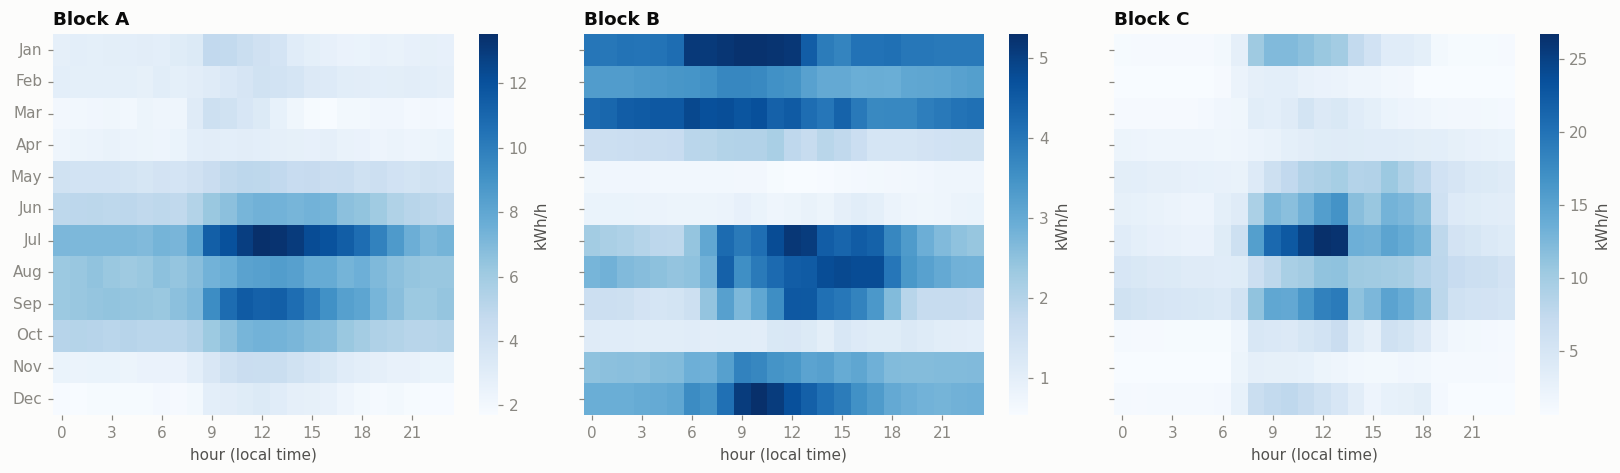

In [31]:
loc_df = df.copy(); loc_df.index = loc_df.index.tz_convert(TZ)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for a, b in zip(ax, BLOCKS):
    p = loc_df.groupby([loc_df.index.month, loc_df.index.hour])[f"kwh_{b}"].mean().unstack()
    p.index = MONTHS
    sns.heatmap(p, cmap="Blues", ax=a, cbar_kws={"label": "kWh/h"}, xticklabels=3)
    a.set_title(f"Block {b}"); a.set_xlabel("hour (local time)"); a.grid(False); a.tick_params(axis="y", rotation=0)
plt.tight_layout(); plt.show()

**Finding:** consumption follows the working day (about 08:00–20:00 local time). In A and C the midday hours of June–September are the darkest cells (cooling at the hottest time). B is strongest on winter mornings and summer middays, and almost idle in April–June and October. A keeps a clear night base load in summer (units left running). **Consequence:** hour of day and season both shape the load, so a model needs **calendar features** as well as weather.

## 5. Gaps and limitations

In [32]:
n_missing = int(df["kwh_total"].isna().sum())
pd.DataFrame([
    ("1 Purpose",           "covered",  "hourly kWh per block (target) + weather + HVAC",                  "–",                                                    "forecast is possible"),
    ("2 System boundary",   "partly",   "3 block meters, 86 HVAC units, 60 room sensors",                  "no split of HVAC vs. lights/computers/labs",           "we model total block energy, not HVAC energy alone"),
    ("3 Inputs u",          "covered",  "on/off, mode, setpoint per unit (V4, V5, V12)",                   f"{sp_share:.0%} setpoints invalid; block C HVAC missing 1–19 May",                             "what-if on settings possible, with care"),
    ("4 Disturbances d",    "partly",   "weather: tmed, hrmed, radmed, vvmed, prec",                       "occupancy, plug loads, use of the building (calendar, closed areas); weather gaps", "unexplained variance; calendar must be added by us"),
    ("5 States x",          "partly",   "room temperature (block mean)",                                   "thermal mass, occupancy, HVAC condition (hidden)",     "slow building response must be inferred, not measured"),
    ("6 Outputs y",         "covered",  "cumulative meter → hourly kWh",                                    f"{n_missing} h missing (outages)",                              "exclude outage hours from training and testing"),
    ("7 Constraints & dynamics", "partly", "setpoints, daily/weekly/seasonal cycles",                       "only one year; no comfort limits recorded",            "each season appears once: fair testing needs care"),
], columns=["canvas box", "coverage", "what the data provides", "what is missing", "meaning for the objective"]).set_index("canvas box")

,coverage,what the data provides,what is missing,meaning for the objective
canvas box,,,,
1 Purpose,covered,hourly kWh per block (target) + weather + HVAC,–,forecast is possible
2 System boundary,partly,"3 block meters, 86 HVAC units, 60 room sensors",no split of HVAC vs. lights/computers/labs,"we model total block energy, not HVAC energy alone"
3 Inputs u,covered,"on/off, mode, setpoint per unit (V4, V5, V12)",13% setpoints invalid; block C HVAC missing 1–19 May,"what-if on settings possible, with care"
4 Disturbances d,partly,"weather: tmed, hrmed, radmed, vvmed, prec","occupancy, plug loads, use of the building (calendar, closed areas); weather...",unexplained variance; calendar must be added by us
5 States x,partly,room temperature (block mean),"thermal mass, occupancy, HVAC condition (hidden)","slow building response must be inferred, not measured"
6 Outputs y,covered,cumulative meter → hourly kWh,161 h missing (outages),exclude outage hours from training and testing
7 Constraints & dynamics,partly,"setpoints, daily/weekly/seasonal cycles",only one year; no comfort limits recorded,each season appears once: fair testing needs care


**Summary**
* The data covers the **core chain** of the objective: outputs (hourly energy per block), controllable inputs (HVAC settings) and the main disturbance (weather).
* **Not covered:** occupancy and plug loads, the split of block energy into HVAC and other loads, and the building's thermal storage. These limit how much of the load a model can explain, and they keep the twin at the level of a **digital model** until such signals exist.
* **One year only:** every season appears once, so a model can be tested on later weeks, but not on the same season of a new year.
* **Practical scope:** 1 Jan – 17 Dec 2021, outage hours excluded, one model per block.